In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Path to cleaned datasets
DATA_PATH = Path("../data/clean")

# Load all five cleaned datasets
customers = pd.read_csv(DATA_PATH / "customers_clean.csv")
accounts = pd.read_csv(DATA_PATH / "accounts_clean.csv")
branches = pd.read_csv(DATA_PATH / "branches_clean.csv")
loans = pd.read_csv(DATA_PATH / "loans_clean.csv")
transactions = pd.read_csv(DATA_PATH / "transactions_clean.csv")

print("All cleaned datasets loaded successfully!")

All cleaned datasets loaded successfully!


In [3]:
datasets = {
    "Customers": customers,
    "Accounts": accounts,
    "Branches": branches,
    "Loans": loans,
    "Transactions": transactions
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Customers: 75,000 rows × 13 columns
Accounts: 85,000 rows × 7 columns
Branches: 100 rows × 6 columns
Loans: 30,000 rows × 10 columns
Transactions: 500,000 rows × 9 columns


In [4]:
# View the first five loan records
display(loans.head())

# Check column names and data types
loans.info()

# View the available loan columns
print("\nLoan columns:")
print(loans.columns.tolist())

,loan_id,customer_id,loan_type,loan_amount,interest_rate,emi,credit_score,loan_status,default_flag,remaining_balance
0,L00001,C15796,Personal Loan,3000,0.1054,65,782,Active,No,600
1,L00002,C00861,Education Loan,10000,0.0805,244,713,Active,No,6400
2,L00003,C05391,Education Loan,18000,0.0945,294,647,Closed,No,0
3,L00004,C21576,Education Loan,34000,0.1002,450,620,Active,No,21900
4,L00005,C11965,Home Loan,350000,0.0737,3219,638,Closed,No,0


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   loan_id            30000 non-null  str    
 1   customer_id        30000 non-null  str    
 2   loan_type          30000 non-null  str    
 3   loan_amount        30000 non-null  int64  
 4   interest_rate      30000 non-null  float64
 5   emi                30000 non-null  int64  
 6   credit_score       30000 non-null  int64  
 7   loan_status        30000 non-null  str    
 8   default_flag       30000 non-null  str    
 9   remaining_balance  30000 non-null  int64  
dtypes: float64(1), int64(4), str(5)
memory usage: 2.3 MB

Loan columns:
['loan_id', 'customer_id', 'loan_type', 'loan_amount', 'interest_rate', 'emi', 'credit_score', 'loan_status', 'default_flag', 'remaining_balance']


In [5]:
# Check how defaults are recorded
print("Default flag values:")
display(loans["default_flag"].value_counts(dropna=False))

print("\nLoan status values:")
display(loans["loan_status"].value_counts(dropna=False))

print("\nDefault flag data type:")
print(loans["default_flag"].dtype)

Default flag values:


default_flag
No     28383
Yes     1617
Name: count, dtype: int64


Loan status values:


loan_status
Active       20948
Closed        8600
Defaulted      452
Name: count, dtype: int64


Default flag data type:
str


In [6]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Prepare categorical and numerical features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Build a machine learning pipeline
from sklearn.pipeline import Pipeline

# ML models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluate model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

In [7]:
# Select useful customer features
customer_features = customers[
    [
        "customer_id",
        "age",
        "annual_income",
        "occupation",
        "marital_status",
        "customer_segment"
    ]
]

# Combine loans with customer information
ml_data = loans.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("ML dataset created successfully!")
print("Rows:", f"{ml_data.shape[0]:,}")
print("Columns:", ml_data.shape[1])

display(ml_data.head())

ML dataset created successfully!
Rows: 30,000
Columns: 15


,loan_id,customer_id,loan_type,loan_amount,interest_rate,emi,credit_score,loan_status,default_flag,remaining_balance,age,annual_income,occupation,marital_status,customer_segment
0,L00001,C15796,Personal Loan,3000,0.1054,65,782,Active,No,600,63,630000,Teacher,Single,Silver
1,L00002,C00861,Education Loan,10000,0.0805,244,713,Active,No,6400,29,590000,Sales Executive,Single,Silver
2,L00003,C05391,Education Loan,18000,0.0945,294,647,Closed,No,0,24,920000,Architect,Single,Gold
3,L00004,C21576,Education Loan,34000,0.1002,450,620,Active,No,21900,35,1720000,Data Scientist,Single,Platinum
4,L00005,C11965,Home Loan,350000,0.0737,3219,638,Closed,No,0,45,1400000,Architect,Married,Platinum


In [8]:
# Define the target variable
y = ml_data["default_flag"].map({
    "No": 0,
    "Yes": 1
})

# Select input features
feature_columns = [
    "loan_type",
    "loan_amount",
    "interest_rate",
    "emi",
    "credit_score",
    "age",
    "annual_income",
    "occupation",
    "marital_status",
    "customer_segment"
]

X = ml_data[feature_columns].copy()

print("Features (X):", X.shape)
print("Target (y):", y.shape)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "No Default", 1: "Default"}))

print("\nMissing target values:", y.isna().sum())
print("\nSelected features:")
print(X.columns.tolist())

Features (X): (30000, 10)
Target (y): (30000,)

Target distribution:


default_flag
No Default    28383
Default        1617
Name: count, dtype: int64


Missing target values: 0

Selected features:
['loan_type', 'loan_amount', 'interest_rate', 'emi', 'credit_score', 'age', 'annual_income', 'occupation', 'marital_status', 'customer_segment']


In [9]:
# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: "No Default", 1: "Default"}))

print("\nTesting target distribution:")
display(y_test.value_counts().rename(index={0: "No Default", 1: "Default"}))

Training features: (24000, 10)
Testing features: (6000, 10)

Training target distribution:


default_flag
No Default    22706
Default        1294
Name: count, dtype: int64


Testing target distribution:


default_flag
No Default    5677
Default        323
Name: count, dtype: int64

In [10]:
# Identify numerical and categorical columns
numerical_features = [
    "loan_amount",
    "interest_rate",
    "emi",
    "credit_score",
    "age",
    "annual_income"
]

categorical_features = [
    "loan_type",
    "occupation",
    "marital_status",
    "customer_segment"
]

# Preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessor created successfully!")

Numerical features: 6
Categorical features: 4
Preprocessor created successfully!


In [11]:
# Create the Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [12]:
# Predict on the test dataset
y_pred_lr = logistic_model.predict(X_test)

# Calculate default probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
print("LOGISTIC REGRESSION RESULTS")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Default", "Default"],
    zero_division=0
))

LOGISTIC REGRESSION RESULTS
-----------------------------------


Accuracy:  0.7023
Precision: 0.1212
Recall:    0.7245
F1-score:  0.2076
ROC-AUC:   0.7777

Classification Report:
              precision    recall  f1-score   support

  No Default       0.98      0.70      0.82      5677
     Default       0.12      0.72      0.21       323

    accuracy                           0.70      6000
   macro avg       0.55      0.71      0.51      6000
weighted avg       0.93      0.70      0.78      6000



In [13]:
# Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [14]:
# Predict default outcomes
y_pred_rf = random_forest_model.predict(X_test)

# Predict default probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
print("RANDOM FOREST RESULTS")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Default", "Default"],
    zero_division=0
))

RANDOM FOREST RESULTS
-----------------------------------
Accuracy:  0.9357
Precision: 0.2056
Recall:    0.0681
F1-score:  0.1023
ROC-AUC:   0.7648

Classification Report:
              precision    recall  f1-score   support

  No Default       0.95      0.99      0.97      5677
     Default       0.21      0.07      0.10       323

    accuracy                           0.94      6000
   macro avg       0.58      0.53      0.53      6000
weighted avg       0.91      0.94      0.92      6000



In [15]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_comparison = model_comparison.round(4)

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7023,0.1212,0.7245,0.2076,0.7777
1,Random Forest,0.9357,0.2056,0.0681,0.1023,0.7648


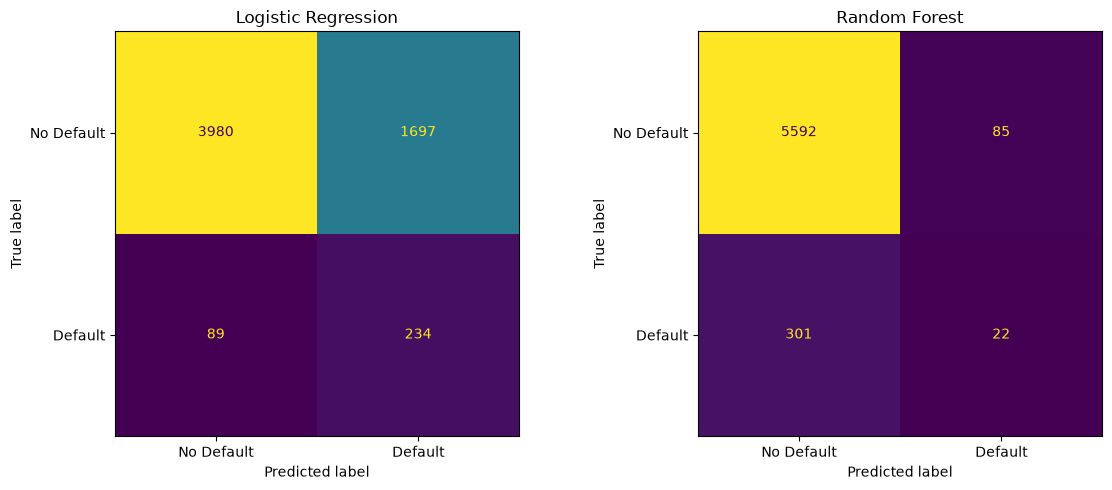

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=["No Default", "Default"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=["No Default", "Default"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import confusion_matrix

# Use a lower threshold for predicting default
threshold = 0.30

y_pred_lr_30 = (y_prob_lr >= threshold).astype(int)

print("LOGISTIC REGRESSION — THRESHOLD 0.30")
print("-" * 45)

print(f"Precision: {precision_score(y_test, y_pred_lr_30, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr_30, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr_30, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_30))

LOGISTIC REGRESSION — THRESHOLD 0.30
---------------------------------------------
Precision: 0.0887
Recall:    0.9164
F1-score:  0.1617

Confusion Matrix:
[[2636 3041]
 [  27  296]]


In [18]:
threshold_results = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "False Alarms": confusion_matrix(
            y_test, y_pred_threshold
        )[0, 1],
        "Missed Defaults": confusion_matrix(
            y_test, y_pred_threshold
        )[1, 0]
    })

threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1-Score,False Alarms,Missed Defaults
0,0.2,0.0736,0.9628,0.1368,3914,12
1,0.3,0.0887,0.9164,0.1617,3041,27
2,0.4,0.1064,0.8576,0.1893,2326,46
3,0.5,0.1212,0.7245,0.2076,1697,89
4,0.6,0.1324,0.5511,0.2136,1166,145
5,0.7,0.1559,0.4025,0.2247,704,193


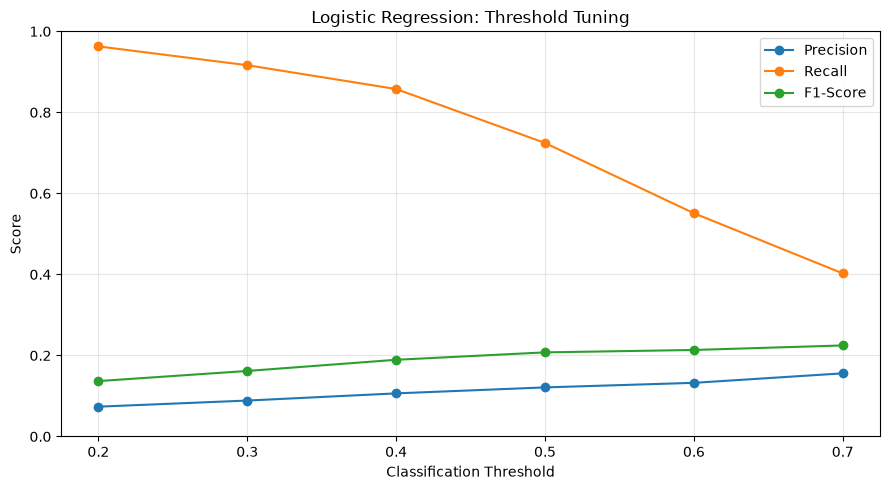

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Tuning")
plt.xticks(threshold_comparison["Threshold"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Get the fitted preprocessing step
fitted_preprocessor = logistic_model.named_steps["preprocessor"]

# Get feature names after scaling and one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_model.named_steps["classifier"].coef_[0]

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Abs_Coefficient",
    ascending=False
)

display(feature_importance.head(15).round(4))

,Feature,Coefficient,Abs_Coefficient
3,num__credit_score,-1.2782,1.2782
17,cat__occupation_Doctor,-0.2414,0.2414
23,cat__occupation_Sales Executive,0.2393,0.2393
11,cat__occupation_Architect,0.2351,0.2351
27,cat__marital_status_Single,-0.2270,0.2270
30,cat__customer_segment_Silver,-0.2229,0.2229
21,cat__occupation_Marketing Manager,-0.2012,0.2012
14,cat__occupation_Civil Engineer,-0.1978,0.1978
13,cat__occupation_Chartered Accountant,-0.1873,0.1873
22,cat__occupation_Operations Manager,-0.1838,0.1838


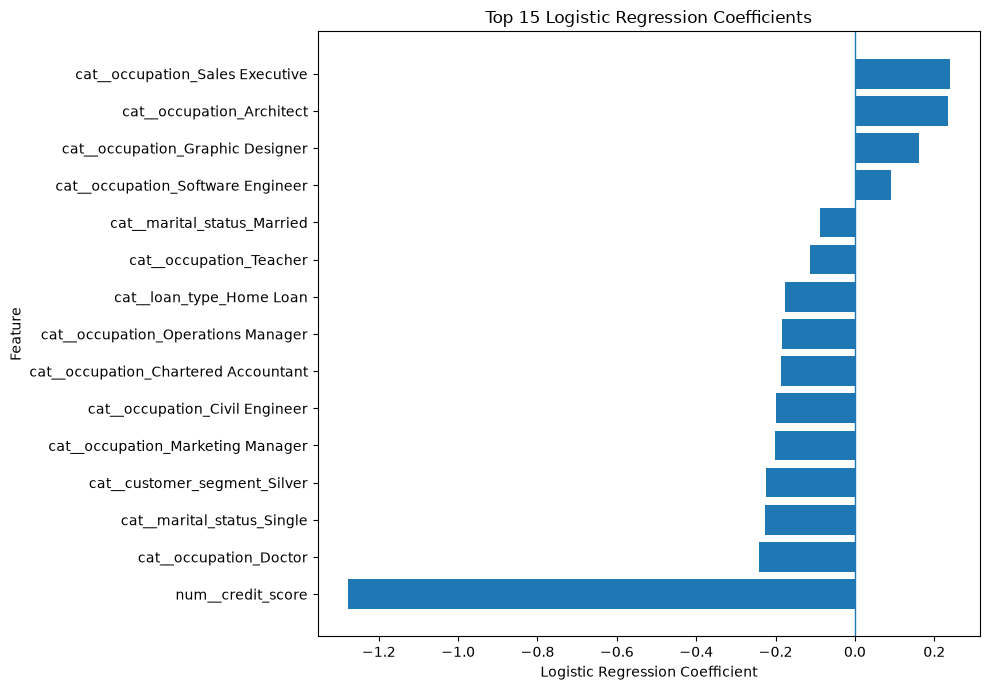

In [21]:


top_features = (
    feature_importance
    .head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

In [22]:
# Get the fitted preprocessing step from Random Forest
rf_preprocessor = random_forest_model.named_steps["preprocessor"]

# Get feature names after preprocessing
rf_feature_names = rf_preprocessor.get_feature_names_out()

# Get feature importance scores
rf_importances = (
    random_forest_model.named_steps["classifier"].feature_importances_
)

# Create feature importance table
rf_feature_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Sort from most important to least important
rf_feature_importance = rf_feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(rf_feature_importance.head(15).round(4))

,Feature,Importance
3,num__credit_score,0.3177
1,num__interest_rate,0.1544
2,num__emi,0.1078
5,num__annual_income,0.0984
4,num__age,0.0874
0,num__loan_amount,0.0835
28,cat__customer_segment_Gold,0.0080
26,cat__marital_status_Married,0.0078
27,cat__marital_status_Single,0.0077
24,cat__occupation_Software Engineer,0.0074


In [23]:
from pathlib import Path

# Create the ML reports folder
output_dir = Path("../ml/output")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save model comparison
model_comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# 2. Save threshold comparison
threshold_comparison.to_csv(
    output_dir / "threshold_comparison.csv",
    index=False
)

# 3. Save Logistic Regression coefficients
feature_importance.to_csv(
    output_dir / "logistic_regression_coefficients.csv",
    index=False
)

# 4. Save Random Forest feature importance
rf_feature_importance.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

print("ML results saved successfully!")
print(f"Output folder: {output_dir.resolve()}")
print("\nFiles saved:")
for file_path in sorted(output_dir.glob("*.csv")):
    print("-", file_path.name)

ML results saved successfully!
Output folder: C:\Users\Admin\OneDrive\Desktop\Project\Banking-Customer-Risk-Analytics\ml\output

Files saved:
- logistic_regression_coefficients.csv
- model_comparison.csv
- random_forest_feature_importance.csv
- threshold_comparison.csv


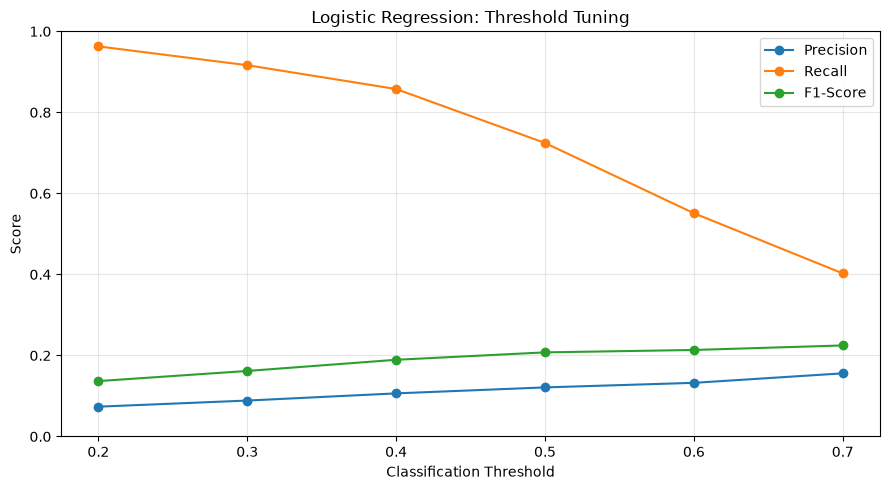

Threshold chart saved!


In [24]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("../ml/output")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Threshold comparison chart
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Tuning")
plt.xticks(threshold_comparison["Threshold"])
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "threshold_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Threshold chart saved!")